<a href="https://colab.research.google.com/github/sankalplohe-ai/loan-default-prediction/blob/main/Default_loan_prediction_csv_updated.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Upload Default_loan_prediction.csv


Saving default loan prediction.csv.csv to default loan prediction.csv (2).csv
Shape: (10000, 5)


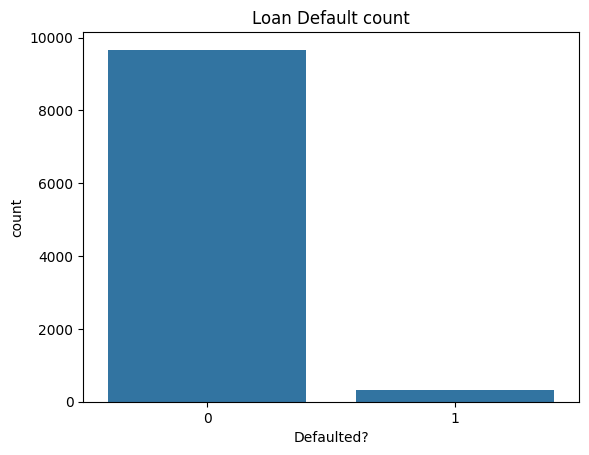

Defaulted?
0    9667
1     333
Name: count, dtype: int64
Defaulted?
0    0.967
1    0.033
Name: proportion, dtype: float64

===== BASELINE: plain Logistic Regression =====
Accuracy: 0.9733
[[2895   11]
 [  69   25]]
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      2906
           1       0.69      0.27      0.38        94

    accuracy                           0.97      3000
   macro avg       0.84      0.63      0.69      3000
weighted avg       0.97      0.97      0.97      3000

Always-'no default' accuracy: 0.9687

===== IMPROVED MODELS (defaulter class) =====
              Model  Accuracy  Precision  Recall    F1  ROC-AUC
Logistic Regression     0.863      0.182    0.89 0.303    0.951
      Decision Tree     0.849      0.159    0.82 0.266    0.885
      Random Forest     0.967      0.517    0.31 0.388    0.891

--- Logistic Regression ---
[[2501  399]
 [  11   89]]
              precision    recall  f1-score   support

      

In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report)

# ===== 1. LOAD DATA =====
FILE = "Default_loan_prediction.csv"
paths = [FILE, "/content/" + FILE, "/content/drive/MyDrive/" + FILE]
path = next((p for p in paths if os.path.exists(p)), None)
if path is None:
    from google.colab import files
    print("Upload Default_loan_prediction.csv")
    path = list(files.upload().keys())[0]

df = pd.read_csv(path)
df.columns = df.columns.str.strip()
df = df.dropna().drop_duplicates()
print("Shape:", df.shape)

# ===== 2. EDA =====
sns.countplot(x="Defaulted?", data=df)
plt.title("Loan Default count")
plt.show()
print(df["Defaulted?"].value_counts())
print(df["Defaulted?"].value_counts(normalize=True).round(3))

# ===== 3. FEATURES / TARGET (Index column excluded) =====
X = df[["Employed", "Bank Balance", "Annual Salary"]]
y = df["Defaulted?"]

# ===== 4. BASELINE (your original model, kept as "before") =====
Xb_train, Xb_test, yb_train, yb_test = train_test_split(X, y, test_size=0.3, random_state=42)
base = LogisticRegression().fit(Xb_train, yb_train)
pb = base.predict(Xb_test)
print("\n===== BASELINE: plain Logistic Regression =====")
print("Accuracy:", round(accuracy_score(yb_test, pb), 4))
print(confusion_matrix(yb_test, pb))
print(classification_report(yb_test, pb))
print("Always-'no default' accuracy:", round((yb_test == 0).mean(), 4))

# ===== 5. IMPROVED: stratified split + scaling + class weights =====
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

lr = LogisticRegression(class_weight="balanced", max_iter=1000).fit(X_train_s, y_train)
dt = DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42).fit(X_train, y_train)
rf = RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42).fit(X_train, y_train)

models = [("Logistic Regression", lr, X_test_s),
          ("Decision Tree", dt, X_test),
          ("Random Forest", rf, X_test)]

rows = []
for name, m, Xt in models:
    p = m.predict(Xt)
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(y_test, p),
                 "Precision": precision_score(y_test, p, zero_division=0),
                 "Recall": recall_score(y_test, p),
                 "F1": f1_score(y_test, p),
                 "ROC-AUC": roc_auc_score(y_test, m.predict_proba(Xt)[:, 1])})

print("\n===== IMPROVED MODELS (defaulter class) =====")
print(pd.DataFrame(rows).round(3).to_string(index=False))

for name, m, Xt in models:
    print(f"\n--- {name} ---")
    print(confusion_matrix(y_test, m.predict(Xt)))
    print(classification_report(y_test, m.predict(Xt)))

# ===== 6. FEATURE IMPORTANCE =====
print("\nRandom Forest feature importance:")
print(pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).round(3))
print("\nDecision Tree feature importance:")
print(pd.Series(dt.feature_importances_, index=X.columns).sort_values(ascending=False).round(3))



